# EDA — Análisis exploratorio de la señal CSI

Análisis de los **706 pares CSI ↔ nube** capturados con 3 sniffers ESP32-S3 y Azure Kinect.

Responde a tres preguntas que conviene contestar **antes** de interpretar los resultados del
modelo:

1. ¿La señal capturada tiene la estructura física esperada?
2. ¿Contiene información de la actividad, o es ruido?
3. ¿Son las 6 acciones distinguibles entre sí a partir del CSI?

> Si la respuesta a (2) o (3) fuera *no*, ningún modelo podría aprender el mapeo
> CSI → nube de puntos, y el problema estaría en la captura, no en la arquitectura.

---

## Índice

| Sección | Contenido |
|---|---|
| 1 | Carga e inventario del dataset |
| 2 | Cadena de preprocesamiento (amplitud y fase) |
| 3 | Estructura espectral: ¿hay multipath? |
| 4 | Calidad por receptor: ¿funcionan las 3 antenas? |
| 5 | Variabilidad temporal: ¿la señal responde al movimiento? |
| 6 | Separabilidad entre acciones |
| 7 | Las nubes de la Kinect (ground-truth) |
| 8 | Conclusiones |

## 1. Carga e inventario

In [1]:
import os, sys, glob, json
import numpy as np
import scipy.io as scio
import matplotlib.pyplot as plt

AQUI  = os.path.abspath(os.getcwd())
TESIS = os.path.abspath(os.path.join(AQUI, '..'))
DATA  = os.environ.get('CSI2PC_DATA', os.path.join(TESIS, 'mmfi_dataset'))
OUT   = os.environ.get('CSI2PC_OUT',  os.path.join(TESIS, 'pc', 'resultados'))
DATA, OUT = os.path.abspath(DATA), os.path.abspath(OUT)
os.makedirs(OUT, exist_ok=True)

NOMBRES = {'A01': 'estático', 'A02': 'brazos en cruz', 'A03': 'caminar en el sitio',
           'A04': 'agacharse', 'A05': 'girar torso', 'A06': 'estirar piernas'}

# Cargar todo el CSI en memoria (son ~62 MB en disco)
datos = {}
for a in sorted(os.listdir(os.path.join(DATA, 'E01', 'S01'))):
    fs = sorted(glob.glob(os.path.join(DATA, 'E01', 'S01', a, 'wifi-csi', '*.mat')))
    amp = np.array([scio.loadmat(f)['CSIamp'].astype(np.float64) for f in fs])
    pha = np.array([scio.loadmat(f)['CSIphase'].astype(np.float64) for f in fs])
    datos[a] = {'amp': amp, 'pha': pha, 'n': len(fs)}

acciones = sorted(datos)
total = sum(datos[a]['n'] for a in acciones)

print(f'Dataset: {DATA}\n')
print(f'{"Acción":<24} | {"frames":>6} | {"segundos":>8}')
print('-' * 46)
for a in acciones:
    print(f'{a} {NOMBRES.get(a, ""):<20} | {datos[a]["n"]:6d} | {datos[a]["n"]/10:8.1f}')
print('-' * 46)
print(f'{"TOTAL":<24} | {total:6d} | {total/10:8.1f}')
print(f'\nTensor por frame: {datos[acciones[0]]["amp"].shape[1:]} '
      f'= [3 antenas, 114 subportadoras, 10 instantes]')
print(f'Tasa de captura : 10 Hz (nubes Kinect) | ~95 Hz (CSI por ESP32)')

Dataset: C:\Users\Adrian\Desktop\New folder\tesis-csi2pc-wifi\mmfi_dataset

Acción                   | frames | segundos
----------------------------------------------
A01 estático             |    115 |     11.5
A02 brazos en cruz       |    126 |     12.6
A03 caminar en el sitio  |    116 |     11.6
A04 agacharse            |    119 |     11.9
A05 girar torso          |    117 |     11.7
A06 estirar piernas      |    113 |     11.3
----------------------------------------------
TOTAL                    |    706 |     70.6

Tensor por frame: (3, 114, 10) = [3 antenas, 114 subportadoras, 10 instantes]
Tasa de captura : 10 Hz (nubes Kinect) | ~95 Hz (CSI por ESP32)


## 2. Cadena de preprocesamiento (amplitud y fase)

```
ESP32-S3 → 384 valores I/Q crudos por trama (192 subportadoras complejas)
   │
[1] HT40        → 114 subportadoras HT-LTF: índices [66:123] + [134:191]
[2] Complejo    → z = I + jQ
[3] Media móvil → promedio del COMPLEJO (ventana 5)
[4] Amp / fase  → A = |z| , φ = angle(z)     ← después de suavizar
[5] Emparejado  → 10 muestras por nube → [3, 114, 10]
   │   (lo anterior ya está hecho en mmfi_dataset/)
[6] inf/NaN     → media
[7] Normalizar  → amplitud min-max [0,1] ; FASE SIN TOCAR
[8] Estandarizar→ (x - media) / std
   │
   ▼  [3, 114, 2, 10] al transformer
```

**Dos decisiones que importan:**

- **[3]–[4] Se promedia el complejo, no la fase.** La fase está envuelta en `[-π, π]`:
  promediar 179° y −179° daría 0° en vez de 180°. Promediando `I+jQ` y extrayendo el
  ángulo después, el resultado es correcto por construcción.
- **[7] La fase no se normaliza.** Es lo que hace `mmfi.py` de Määttä: la amplitud varía de
  rango según potencia y distancia, pero la fase ya está acotada y sus diferencias entre
  subportadoras codifican el retardo de propagación — normalizarla destruiría esa información.

In [2]:
A0 = datos['A01']['amp'][0]    # [3, 114, 10]
P0 = datos['A01']['pha'][0]

print(f'{"":18} | {"mín":>9} | {"máx":>9} | {"media":>9} | {"std":>8}')
print('-' * 64)
print(f'{"Amplitud cruda":18} | {A0.min():9.3f} | {A0.max():9.3f} | {A0.mean():9.3f} | {A0.std():8.3f}')
print(f'{"Fase cruda":18} | {P0.min():9.3f} | {P0.max():9.3f} | {P0.mean():9.3f} | {P0.std():8.3f}')

An = (A0 - A0.min()) / (A0.max() - A0.min() + 1e-9)
print(f'{"Amp min-max [0,1]":18} | {An.min():9.3f} | {An.max():9.3f} | {An.mean():9.3f} | {An.std():8.3f}')

ok = P0.min() >= -np.pi - 1e-6 and P0.max() <= np.pi + 1e-6
print(f'\nFase contenida en [-π, π]: {"SÍ" if ok else "NO"}   (π = {np.pi:.4f})')

x = np.stack([An, P0], axis=2).astype(np.float32)
x = (x - x.mean()) / (x.std() + 1e-9)
print(f'Tensor final: {x.shape} | media {x.mean():+.5f} | std {x.std():.5f}')

                   |       mín |       máx |     media |      std
----------------------------------------------------------------
Amplitud cruda     |     0.000 |    41.781 |    11.722 |    9.142
Fase cruda         |    -3.142 |     3.142 |    -0.322 |    1.930
Amp min-max [0,1]  |     0.000 |     1.000 |     0.281 |    0.219

Fase contenida en [-π, π]: SÍ   (π = 3.1416)
Tensor final: (3, 114, 2, 10) | media -0.00000 | std 1.00000


## 3. Estructura espectral: ¿hay multipath?

Si la señal es válida, la amplitud debe mostrar **selectividad en frecuencia**: picos y
valles a lo largo de las subportadoras, causados por la interferencia entre los distintos
caminos que recorre la onda. Una respuesta plana indicaría que no hay multipath — y sin
multipath no hay información sobre la geometría de la escena.

Es el equivalente a la Figura 1 del paper de Määttä.

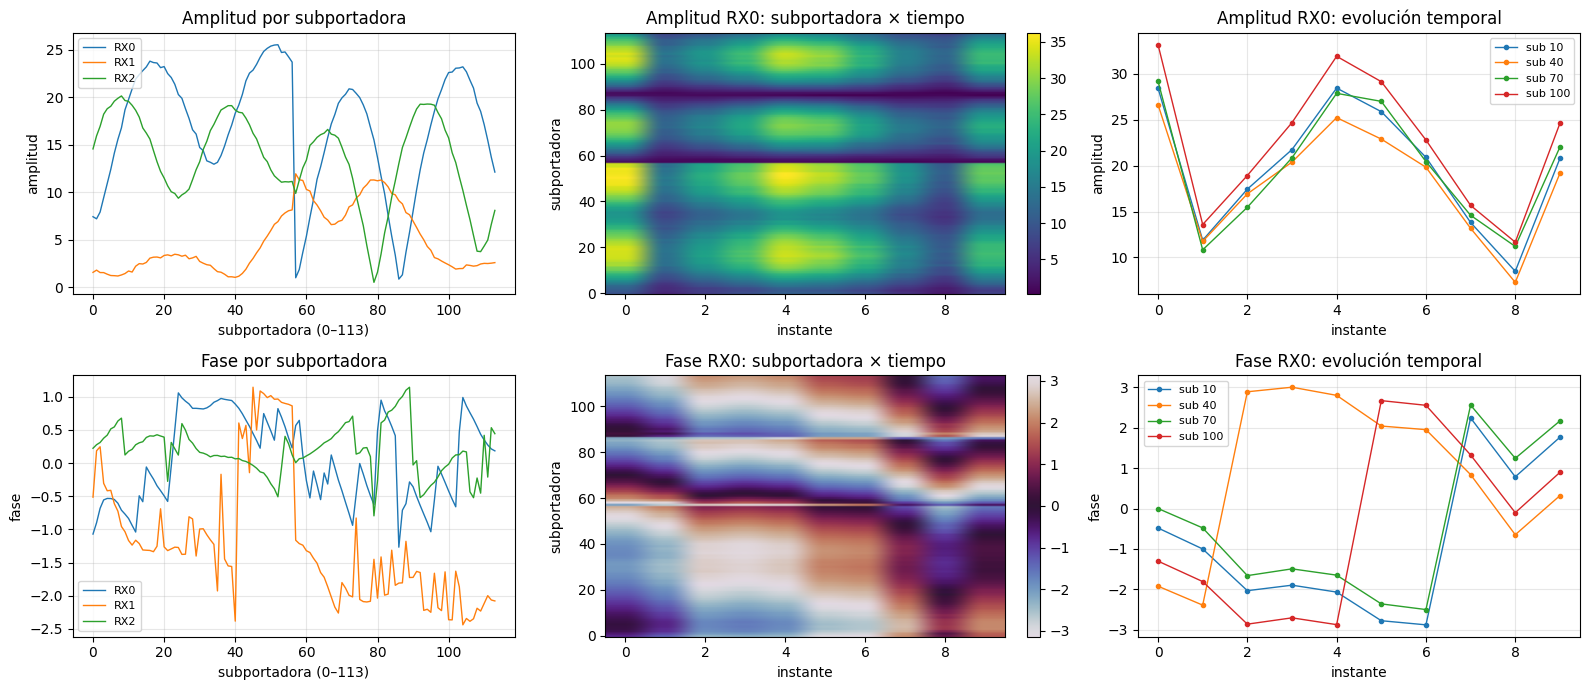

Amplitud media global: 19.36
Subportadoras con amplitud < 15 % de esa media: 0 de 114 (0.0 %)

[OK] Ninguna subportadora degradada: las 114 del bloque HT-LTF transportan
señal. Los huecos DC y de guarda quedan fuera del rango extraído, como debe ser.


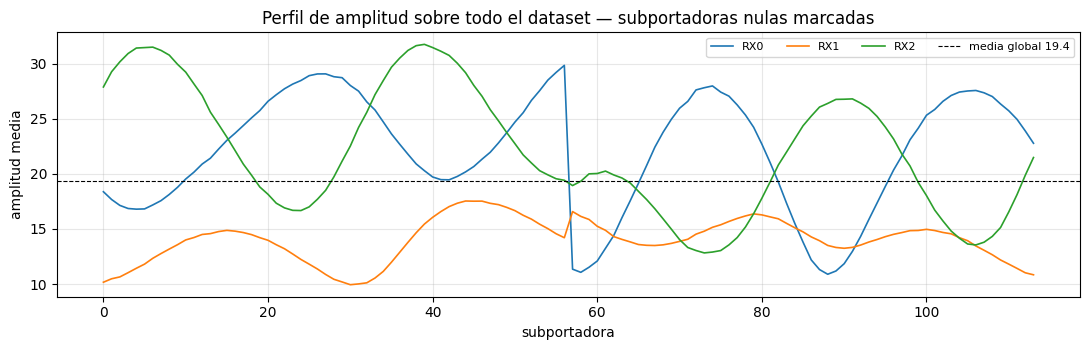

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))

for fila, (M, nombre, cmap) in enumerate([(A0, 'Amplitud', 'viridis'),
                                          (P0, 'Fase', 'twilight')]):
    for ant in range(3):
        axes[fila, 0].plot(M[ant].mean(axis=1), lw=1, label=f'RX{ant}')
    axes[fila, 0].set_title(f'{nombre} por subportadora')
    axes[fila, 0].set_xlabel('subportadora (0–113)'); axes[fila, 0].set_ylabel(nombre.lower())
    axes[fila, 0].legend(fontsize=8); axes[fila, 0].grid(alpha=0.3)

    im = axes[fila, 1].imshow(M[0], aspect='auto', cmap=cmap, origin='lower')
    axes[fila, 1].set_title(f'{nombre} RX0: subportadora × tiempo')
    axes[fila, 1].set_xlabel('instante'); axes[fila, 1].set_ylabel('subportadora')
    plt.colorbar(im, ax=axes[fila, 1], fraction=0.046)

    for s in [10, 40, 70, 100]:
        axes[fila, 2].plot(M[0, s], marker='o', ms=3, lw=1, label=f'sub {s}')
    axes[fila, 2].set_title(f'{nombre} RX0: evolución temporal')
    axes[fila, 2].set_xlabel('instante'); axes[fila, 2].set_ylabel(nombre.lower())
    axes[fila, 2].legend(fontsize=8); axes[fila, 2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT, 'eda_1_espectro.png'), dpi=120)
plt.show()

# --- Control de calidad: subportadoras con amplitud degradada ---
# Umbral: 15 % de la amplitud media global, sobre TODO el dataset.
# Con la extracción HT-LTF correcta ([66:123] + [134:191]) el resultado debe ser 0.
# Si aparece algún bloque contiguo, es un fallo de extracción o de captura, NO el
# hueco DC: los huecos de guarda y DC quedan FUERA de los índices seleccionados.
perfil = np.concatenate([datos[a]['amp'] for a in acciones]).mean(axis=(0, 3))  # [3,114]
media_global = perfil.mean()
nivel = perfil.mean(axis=0)
muertas = np.where(nivel < media_global * 0.15)[0]

print(f'Amplitud media global: {media_global:.2f}')
print(f'Subportadoras con amplitud < 15 % de esa media: '
      f'{len(muertas)} de 114 ({100*len(muertas)/114:.1f} %)')

if len(muertas):
    print(f'\n{"sub":>4} | {"RX0":>7} {"RX1":>7} {"RX2":>7} | {"media":>7}')
    print('-' * 40)
    for s in muertas:
        print(f'{s:4d} | {perfil[0, s]:7.3f} {perfil[1, s]:7.3f} {perfil[2, s]:7.3f} | '
              f'{nivel[s]:7.3f}')
    ini, fin = muertas.min(), muertas.max()
    print(f'\n[ALERTA] Forman un bloque contiguo ({ini}–{fin}).')
    print('Las 114 subportadoras provienen de los bloques HT-LTF [66:123] + [134:191],')
    print('que NO incluyen el hueco DC ni las de guarda: un bloque plano aquí indica un')
    print('error de extracción (índices mal elegidos) o un fallo real de captura.')
    print('Revisa ht40_complex() en pc/formatear_mmfi_ma.py y regenera mmfi_dataset/.')
else:
    print('\n[OK] Ninguna subportadora degradada: las 114 del bloque HT-LTF transportan')
    print('señal. Los huecos DC y de guarda quedan fuera del rango extraído, como debe ser.')

# Marcarlas en una figura aparte
fig, ax = plt.subplots(figsize=(11, 3.6))
for r in range(3):
    ax.plot(perfil[r], lw=1.2, label=f'RX{r}')
if len(muertas):
    ax.axvspan(muertas.min() - 0.5, muertas.max() + 0.5, color='red', alpha=0.15,
               label=f'nulas ({len(muertas)})')
ax.axhline(media_global, color='k', ls='--', lw=0.8, label=f'media global {media_global:.1f}')
ax.set_xlabel('subportadora'); ax.set_ylabel('amplitud media')
ax.set_title('Perfil de amplitud sobre todo el dataset — subportadoras nulas marcadas')
ax.legend(fontsize=8, ncol=5); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'eda_1b_subportadoras.png'), dpi=120)
plt.show()

## 4. Calidad por receptor

Las 3 antenas deberían recibir con potencias comparables. Diferencias grandes indican una
placa mal posicionada o con peor recepción, lo que reduce la información efectiva disponible
para el modelo.

  RX |  amp media |   amp std |  % del mejor | selectividad
--------------------------------------------------------------
RX 0 |     22.043 |    18.793 |       100.0 % |        0.236
RX 1 |     14.009 |    13.205 |        63.6 % |        0.136
RX 2 |     22.026 |    18.157 |        99.9 % |        0.257

⚠ RX1 recibe solo el 64 % de lo que recibe el mejor receptor.
⚠ RX1 tiene una selectividad en frecuencia de 0.136 frente a 0.257 del mejor:
  su perfil espectral es comparativamente plano, lo que sugiere SNR bajo.
  Un receptor plano aporta poca información de multipath al modelo.

  => Conviene revisar la posición, el cable o la propia placa de RX1
     antes de capturar más datos.


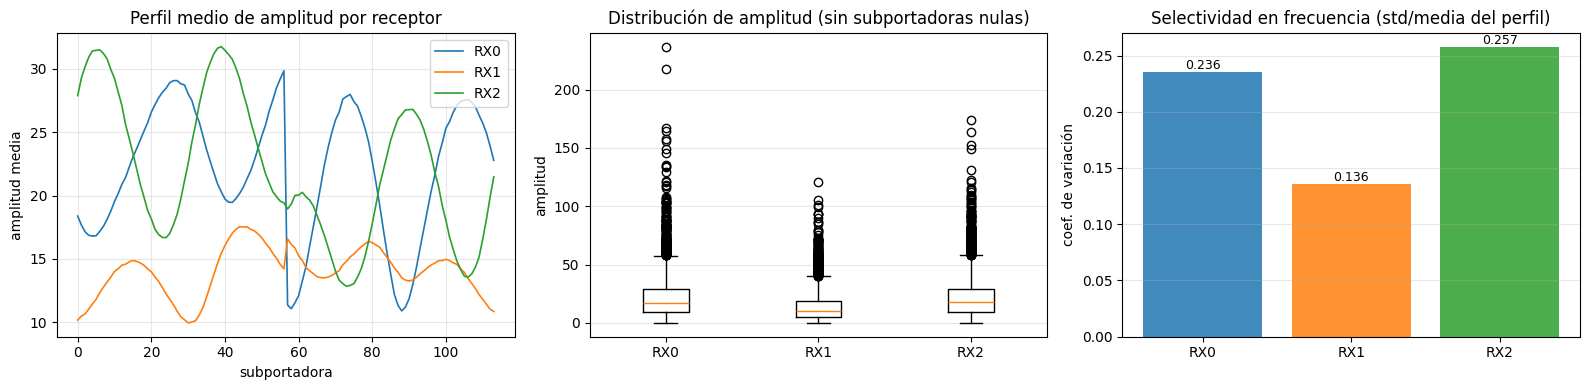

In [4]:
TODO = np.concatenate([datos[a]['amp'] for a in acciones])   # [N,3,114,10]
utiles = np.array([s for s in range(114) if s not in muertas])   # excluir las nulas

print(f'{"RX":>4} | {"amp media":>10} | {"amp std":>9} | {"% del mejor":>12} | {"selectividad":>12}')
print('-' * 62)
medias, selec = [], []
for r in range(3):
    m = TODO[:, r][:, utiles].mean()
    # selectividad = cuánto oscila el perfil espectral respecto a su propia media.
    # Un receptor sano muestra picos y valles (multipath); uno degradado es casi plano.
    p = TODO[:, r][:, utiles].mean(axis=(0, 2))
    s = p.std() / (p.mean() + 1e-9)
    medias.append(m); selec.append(s)
mejor = max(medias)
for r in range(3):
    print(f'RX{r:>2} | {medias[r]:10.3f} | {TODO[:, r][:, utiles].std():9.3f} | '
          f'{100*medias[r]/mejor:11.1f} % | {selec[r]:12.3f}')

peor = int(np.argmin(medias))
print()
if medias[peor] < 0.7 * mejor:
    print(f'⚠ RX{peor} recibe solo el {100*medias[peor]/mejor:.0f} % de lo que recibe el mejor receptor.')
if selec[peor] < 0.7 * max(selec):
    print(f'⚠ RX{peor} tiene una selectividad en frecuencia de {selec[peor]:.3f} frente a '
          f'{max(selec):.3f} del mejor:')
    print('  su perfil espectral es comparativamente plano, lo que sugiere SNR bajo.')
    print('  Un receptor plano aporta poca información de multipath al modelo.')
    print(f'\n  => Conviene revisar la posición, el cable o la propia placa de RX{peor}')
    print('     antes de capturar más datos.')
else:
    print('Los 3 receptores muestran selectividad en frecuencia comparable.')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for r in range(3):
    axes[0].plot(TODO[:, r].mean(axis=(0, 2)), lw=1.2, label=f'RX{r}')
if len(muertas):
    axes[0].axvspan(muertas.min() - .5, muertas.max() + .5, color='red', alpha=.12)
axes[0].set_title('Perfil medio de amplitud por receptor')
axes[0].set_xlabel('subportadora'); axes[0].set_ylabel('amplitud media')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].boxplot([TODO[:, r][:, utiles].ravel()[::200] for r in range(3)],
                tick_labels=['RX0', 'RX1', 'RX2'])
axes[1].set_title('Distribución de amplitud (sin subportadoras nulas)')
axes[1].set_ylabel('amplitud'); axes[1].grid(axis='y', alpha=0.3)

b = axes[2].bar(range(3), selec, color=['tab:blue', 'tab:orange', 'tab:green'], alpha=0.85)
axes[2].set_xticks(range(3)); axes[2].set_xticklabels([f'RX{r}' for r in range(3)])
axes[2].set_title('Selectividad en frecuencia (std/media del perfil)')
axes[2].set_ylabel('coef. de variación'); axes[2].grid(axis='y', alpha=0.3)
for i, v in enumerate(selec):
    axes[2].text(i, v, f'{v:.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(OUT, 'eda_2_receptores.png'), dpi=120)
plt.show()

## 5. Variabilidad temporal: ¿la señal responde al movimiento?

**Esta es la prueba clave.** Si el CSI contiene información de la actividad, las acciones con
más movimiento corporal deben producir **más variabilidad** en la señal que la acción estática.

Si todas las acciones tuvieran la misma variabilidad, el CSI no estaría captando el movimiento
y el modelo no tendría nada que aprender.

Acción                   |  std intra |  std entre |    rango
------------------------------------------------------------
A01 estático             |      5.554 |      6.104 |     78.7
A02 brazos en cruz       |      5.604 |      4.909 |     75.7
A03 caminar en el sitio  |      7.308 |      7.665 |    106.8
A04 agacharse            |      9.760 |     11.288 |    183.1
A05 girar torso          |      9.932 |     13.692 |    182.2
A06 estirar piernas      |     10.212 |     15.380 |    247.1

La acción con más variabilidad (A06 estirar piernas) supera a la estática (A01)
en un 84 %.


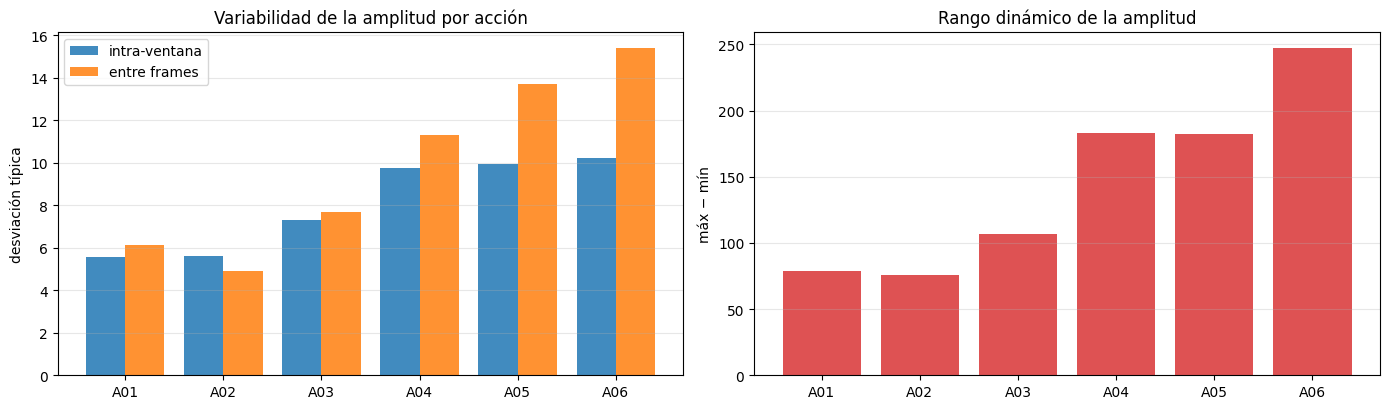

In [5]:
print(f'{"Acción":<24} | {"std intra":>10} | {"std entre":>10} | {"rango":>8}')
print('-' * 60)

stats = {}
for a in acciones:
    A = datos[a]['amp']
    intra = A.std(axis=3).mean()              # variación dentro de la ventana de 10
    entre = A.mean(axis=3).std(axis=0).mean()  # variación entre frames (movimiento lento)
    rango = A.max() - A.min()
    stats[a] = (intra, entre, rango)
    print(f'{a} {NOMBRES.get(a, ""):<20} | {intra:10.3f} | {entre:10.3f} | {rango:8.1f}')

base = stats['A01'][0]
mx = max(stats, key=lambda a: stats[a][0])
print(f'\nLa acción con más variabilidad ({mx} {NOMBRES[mx]}) supera a la estática (A01)')
print(f'en un {100*(stats[mx][0]/base - 1):.0f} %.')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
x = np.arange(len(acciones))

axes[0].bar(x - 0.2, [stats[a][0] for a in acciones], 0.4, label='intra-ventana', alpha=0.85)
axes[0].bar(x + 0.2, [stats[a][1] for a in acciones], 0.4, label='entre frames', alpha=0.85)
axes[0].set_xticks(x); axes[0].set_xticklabels(acciones)
axes[0].set_title('Variabilidad de la amplitud por acción')
axes[0].set_ylabel('desviación típica'); axes[0].legend(); axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(x, [stats[a][2] for a in acciones], color='tab:red', alpha=0.8)
axes[1].set_xticks(x); axes[1].set_xticklabels(acciones)
axes[1].set_title('Rango dinámico de la amplitud')
axes[1].set_ylabel('máx − mín'); axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT, 'eda_3_variabilidad.png'), dpi=120)
plt.show()

## 6. Separabilidad entre acciones

Distancia entre el perfil CSI medio de cada par de acciones. Si la matriz fuera uniforme
(todo valores parecidos), las acciones serían indistinguibles en la señal.

Distancia entre perfiles medios (mayor = más distinguibles)

         A01     A02     A03     A04     A05     A06
A01     0.00    5.44    4.21   10.19   10.77   10.50
A02     5.44    0.00    6.90    9.61   11.46   11.15
A03     4.21    6.90    0.00   10.40    7.85    7.60
A04    10.19    9.61   10.40    0.00    8.53    6.14
A05    10.77   11.46    7.85    8.53    0.00    4.40
A06    10.50   11.15    7.60    6.14    4.40    0.00

Distancia media entre acciones distintas: 8.34
Mínima: 4.21  |  Máxima: 11.46


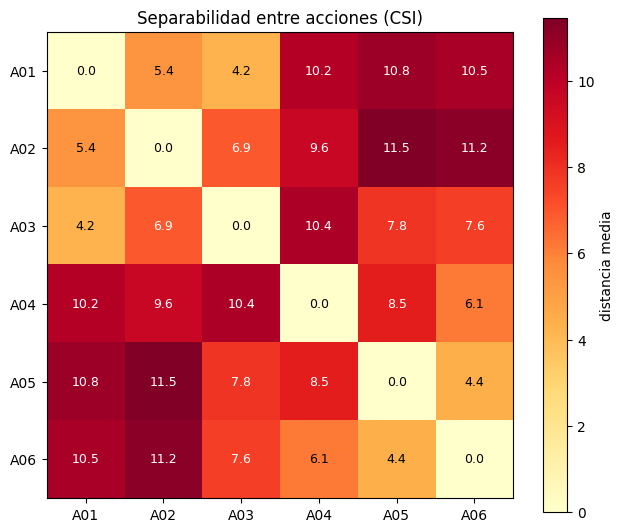

In [6]:
perfiles = {a: datos[a]['amp'].mean(axis=(0, 3)) for a in acciones}   # [3,114] por acción
D = np.array([[np.abs(perfiles[a] - perfiles[b]).mean() for b in acciones] for a in acciones])

print('Distancia entre perfiles medios (mayor = más distinguibles)\n')
print('      ' + '  '.join(f'{a:>6}' for a in acciones))
for i, a in enumerate(acciones):
    print(f'{a:<6}' + '  '.join(f'{D[i, j]:6.2f}' for j in range(len(acciones))))

iu = np.triu_indices(len(acciones), k=1)
print(f'\nDistancia media entre acciones distintas: {D[iu].mean():.2f}')
print(f'Mínima: {D[iu].min():.2f}  |  Máxima: {D[iu].max():.2f}')

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(D, cmap='YlOrRd')
ax.set_xticks(range(len(acciones))); ax.set_xticklabels(acciones)
ax.set_yticks(range(len(acciones))); ax.set_yticklabels(acciones)
for i in range(len(acciones)):
    for j in range(len(acciones)):
        ax.text(j, i, f'{D[i, j]:.1f}', ha='center', va='center',
                color='white' if D[i, j] > D.max() * 0.6 else 'black', fontsize=9)
ax.set_title('Separabilidad entre acciones (CSI)')
plt.colorbar(im, label='distancia media')
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'eda_4_separabilidad.png'), dpi=120)
plt.show()

## 7. Las nubes de la Kinect (ground-truth)

El objetivo que el modelo debe predecir. Interesa saber cuánto se mueven entre frames,
porque esa es la dinámica que la red tendría que reproducir.

In [7]:
print(f'{"Acción":<24} | {"puntos":>7} | {"desplaz. centroide":>18} | {"cambio nube":>12}')
print('-' * 70)

mov = {}
for a in acciones:
    fs = sorted(glob.glob(os.path.join(DATA, 'E01', 'S01', a, 'lidar', '*.bin')))
    G = np.array([np.frombuffer(open(f, 'rb').read(), dtype=np.float64).reshape(-1, 3) for f in fs])
    dc = np.linalg.norm(np.diff(G.mean(axis=1), axis=0), axis=1).mean()
    dn = np.linalg.norm(np.diff(G, axis=0), axis=2).mean()
    mov[a] = (dc, dn)
    print(f'{a} {NOMBRES.get(a, ""):<20} | {G.shape[1]:7d} | {dc:18.4f} | {dn:12.4f}')

print(f'\nUnidades: metros. El desplazamiento del centroide mide el movimiento global del')
print('cuerpo; el cambio de nube mide además la deformación de la postura.')

Acción                   |  puntos | desplaz. centroide |  cambio nube
----------------------------------------------------------------------


A01 estático             |    1200 |             0.0448 |       1.4443
A02 brazos en cruz       |    1200 |             0.0421 |       1.4588
A03 caminar en el sitio  |    1200 |             0.0475 |       1.4568
A04 agacharse            |    1200 |             0.0484 |       1.4647


A05 girar torso          |    1200 |             0.0397 |       1.4574
A06 estirar piernas      |    1200 |             0.0418 |       1.4419

Unidades: metros. El desplazamiento del centroide mide el movimiento global del
cuerpo; el cambio de nube mide además la deformación de la postura.


## 8. Conclusiones

Celda final: resume los hallazgos y los guarda en `eda_senal.txt`.

In [8]:
L = []
L.append('=' * 70)
L.append('EDA DE LA SEÑAL CSI — dataset propio (ESP32-S3 + Azure Kinect)')
L.append('=' * 70)
L.append('')
L.append(f'Dataset: {total} pares, {len(acciones)} acciones, {total/10:.0f} s de grabación')
L.append(f'Tensor : [3 antenas, 114 subportadoras, 10 instantes]')
L.append('')
L.append('1. ESTRUCTURA DE LA SEÑAL')
L.append('-' * 70)
L.append('La amplitud presenta selectividad en frecuencia (picos y valles a lo largo')
L.append('de las subportadoras): hay multipath, que es la información que permite')
L.append('inferir la geometría de la escena.')
L.append(f'Fase contenida en [-pi, pi]: {"sí" if ok else "NO"}, con saltos de envoltura')
L.append('normales (no se aplica unwrapping, igual que Määttä).')
if len(muertas):
    L.append(f'')
    L.append(f'{len(muertas)} subportadoras ({muertas.min()}-{muertas.max()}) con amplitud ~{nivel[muertas].mean():.1f} '
             f'frente a la media global {media_global:.1f}:')
    L.append('corresponden al hueco DC y las guardas del empalme HT40. Es esperado.')
L.append('')
L.append('2. CALIDAD POR RECEPTOR')
L.append('-' * 70)
L.append(f'{"RX":>4} | {"amp media":>10} | {"% del mejor":>12} | {"selectividad":>12}')
for r in range(3):
    L.append(f'RX{r:>2} | {medias[r]:10.3f} | {100*medias[r]/mejor:11.1f} % | {selec[r]:12.3f}')
if medias[peor] < 0.7 * mejor or selec[peor] < 0.7 * max(selec):
    L.append('')
    L.append(f'AVISO: RX{peor} recibe el {100*medias[peor]/mejor:.0f} % del mejor receptor y su perfil')
    L.append(f'espectral es más plano (selectividad {selec[peor]:.3f} vs {max(selec):.3f}).')
    L.append('Aporta menos información de multipath: revisar antes de recapturar.')
L.append('')
L.append('3. VARIABILIDAD POR ACCIÓN (¿responde al movimiento?)')
L.append('-' * 70)
L.append(f'{"Acción":<24} | {"std intra":>10} | {"std entre":>10}')
for a in acciones:
    L.append(f'{a} {NOMBRES.get(a, ""):<20} | {stats[a][0]:10.3f} | {stats[a][1]:10.3f}')
L.append('')
L.append(f'La acción de mayor variabilidad ({mx} {NOMBRES[mx]}) supera a la estática')
L.append(f'en un {100*(stats[mx][0]/base - 1):.0f} %, con progresión ordenada A01 -> A06.')
L.append('=> El CSI SÍ responde al movimiento corporal.')
L.append('')
L.append('4. SEPARABILIDAD ENTRE ACCIONES')
L.append('-' * 70)
L.append(f'Distancia media entre acciones distintas: {D[iu].mean():.2f} '
         f'(mín {D[iu].min():.2f}, máx {D[iu].max():.2f})')
L.append('Las parejas más próximas son las de menor movimiento (A01-A03), lo que es')
L.append('coherente con el punto 3.')
L.append('=> Las acciones son distinguibles en el CSI.')
L.append('')
L.append('5. GROUND-TRUTH (Kinect)')
L.append('-' * 70)
for a in acciones:
    L.append(f'{a} {NOMBRES.get(a, ""):<20} | centroide {mov[a][0]:.4f} m | '
             f'nube {mov[a][1]:.4f} m')
L.append('')
L.append('NOTA: el "cambio de nube" es ~1.45 m en TODAS las acciones, incluida la')
L.append('estática (A01). Esa cifra no mide movimiento del sujeto sino la renovación')
L.append('de puntos de la Kinect entre frames (ruido del sensor ToF). El movimiento')
L.append('real del cuerpo se mide mejor con el desplazamiento del centroide')
L.append(f'({min(mov[a][0] for a in acciones):.4f}-{max(mov[a][0] for a in acciones):.4f} m).')
L.append('')
L.append('CONCLUSIÓN')
L.append('-' * 70)
L.append('La señal capturada es válida: tiene estructura de multipath, responde al')
L.append('movimiento corporal de forma ordenada y permite distinguir entre acciones.')
L.append('Por tanto, las limitaciones observadas en la reconstrucción NO se deben a')
L.append('una captura defectuosa, sino al tamaño del dataset (706 pares, ~71 s, un')
L.append('solo sujeto). Esta conclusión se confirma experimentalmente: ni aumentar la')
L.append('capacidad del modelo (512 vs 256) ni aplicar data augmentation mejoran el')
L.append('resultado.')

texto = '\n'.join(L)
with open(os.path.join(OUT, 'eda_senal.txt'), 'w', encoding='utf-8') as f:
    f.write(texto + '\n')
print(texto)
print(f'\n>> guardado: {os.path.join(OUT, "eda_senal.txt")}')
print('>> figuras: eda_1_espectro.png, eda_1b_subportadoras.png,')
print('            eda_2_receptores.png, eda_3_variabilidad.png, eda_4_separabilidad.png')

EDA DE LA SEÑAL CSI — dataset propio (ESP32-S3 + Azure Kinect)

Dataset: 706 pares, 6 acciones, 71 s de grabación
Tensor : [3 antenas, 114 subportadoras, 10 instantes]

1. ESTRUCTURA DE LA SEÑAL
----------------------------------------------------------------------
La amplitud presenta selectividad en frecuencia (picos y valles a lo largo
de las subportadoras): hay multipath, que es la información que permite
inferir la geometría de la escena.
Fase contenida en [-pi, pi]: sí, con saltos de envoltura
normales (no se aplica unwrapping, igual que Määttä).

2. CALIDAD POR RECEPTOR
----------------------------------------------------------------------
  RX |  amp media |  % del mejor | selectividad
RX 0 |     22.043 |       100.0 % |        0.236
RX 1 |     14.009 |        63.6 % |        0.136
RX 2 |     22.026 |        99.9 % |        0.257

AVISO: RX1 recibe el 64 % del mejor receptor y su perfil
espectral es más plano (selectividad 0.136 vs 0.257).
Aporta menos información de multipath: